<a href="https://colab.research.google.com/github/vaishnavii-25/VDUI-Assignment-Unit-3/blob/ppt1/PES2UG24CS517_unit3_ppt1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [16]:
import pandas as pd

# TODO 1: one 1080p RGB frame, in MB
frame_mb = (1920 * 1080 * 3 * 1) / (1024 * 1024)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 60 * 60 * 24

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = (400 * frames_per_day * frame_mb * 1024 * 1024) / (1024**4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = (400 * (10 * 60 * 60 * 24) * (640 * 360 * 3 * 1)) / (1024**4)
pct_pixels_remaining = ((640 * 360) / (1920 * 1080)) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


In [17]:
# Task 1 Calculations
frame_mb = (1920 * 1080 * 3 * 1) / (1024 * 1024)
frames_per_day = 30 * 60 * 60 * 24
fleet_tb = (400 * frames_per_day * frame_mb * 1024 * 1024) / (1024**4)
fleet_tb_small = (400 * (10 * 60 * 60 * 24) * (640 * 360 * 3 * 1)) / (1024**4)
pct_pixels_remaining = ((640 * 360) / (1920 * 1080)) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37 (raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal** piece of evidence the security team could lose forever by making that choice.

_Your answer:_
- **Spatial loss:** Fine pixel-level detail such as license plates or facial features will be lost forever due to low resolution (raster interpolation blur).
- **Temporal loss:** High-speed actions or micro-expressions (such as the exact moment a weapon is pulled or a specific hand gesture) will be missed because of the lower frame rate (the correspondence problem).

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

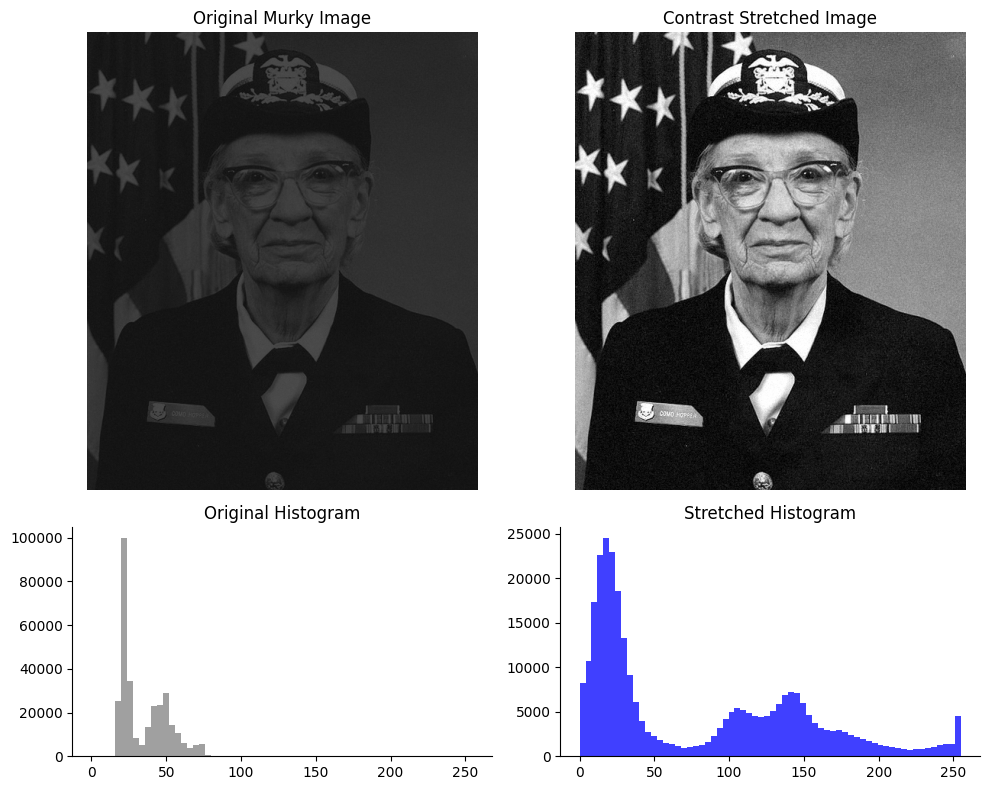

Contrast before: 0.609  ->  after: 1.000


In [18]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) * (255.0 / (p99 - p1)), 0, 255)
p1_new, p99_new = np.percentile(stretched, [1, 99])
c_after = michelson(p99_new, p1_new)

# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})

axes[0, 0].imshow(night_still, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Original Murky Image")
axes[0, 0].axis('off')

axes[0, 1].imshow(stretched, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title("Contrast Stretched Image")
axes[0, 1].axis('off')

axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color='gray', alpha=0.75)
axes[1, 0].set_title("Original Histogram")

axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color='blue', alpha=0.75)
axes[1, 1].set_title("Stretched Histogram")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

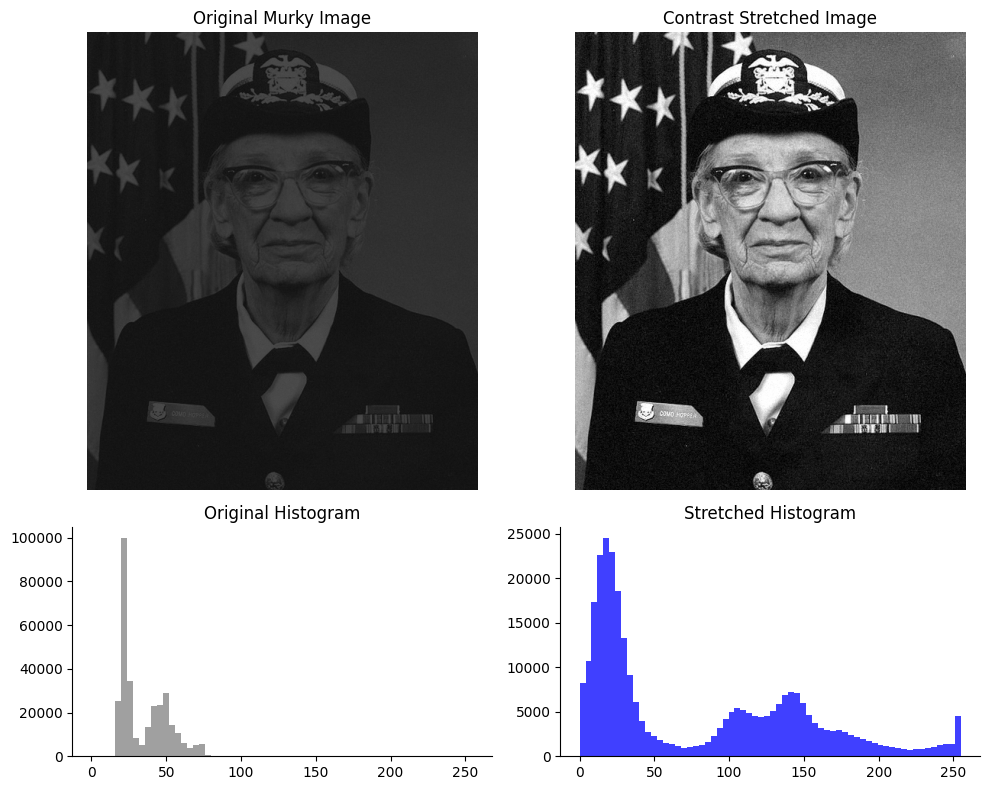

Contrast before: 0.609  ->  after: 1.000


In [19]:
# Task 2 Calculations & Plots
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# Stretch and clip
stretched = np.clip((night_still - p1) * (255.0 / (p99 - p1)), 0, 255)
p1_new, p99_new = np.percentile(stretched, [1, 99])
c_after = michelson(p99_new, p1_new)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
axes[0, 0].imshow(night_still, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Original Murky Image")
axes[0, 0].axis('off')

axes[0, 1].imshow(stretched, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title("Contrast Stretched Image")
axes[0, 1].axis('off')

axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color='gray', alpha=0.75)
axes[1, 0].set_title("Original Histogram")

axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color='blue', alpha=0.75)
axes[1, 1].set_title("Stretched Histogram")

plt.tight_layout()
plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table). Then explain why stretching made the image readable even though it added **no new information** — and why a histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_ The original histogram has a **narrow, uni-modal** distribution concentrated in a very dark range (low-key). Stretching maps this small, active range across the entire 0-255 spectrum, expanding the dynamic range to make detail visible to the human eye, even though it adds no information. A histogram alone cannot tell us what is in the picture because spatial arrangement is discarded; rearranging the pixels yields the exact same histogram but entirely different content.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing: 68.70s to 78.10s
Running: 78.60s to 86.00s


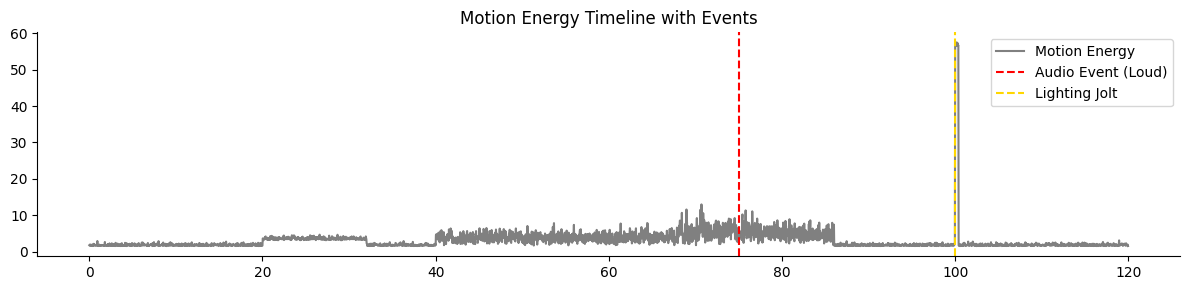

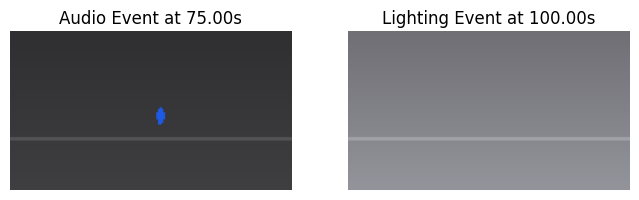

In [20]:
# TODO 1: person speed (px/s)
d_x = cctv['person_x'].diff(FPS)
d_y = cctv['person_y'].diff(FPS)
d_t = cctv['time_s'].diff(FPS)
speed = np.sqrt(d_x**2 + d_y**2) / d_t

# TODO 2: standing / running time ranges (print the first and last time of each)
standing_times = cctv.loc[speed < 3, 'time_s']
running_times = cctv.loc[speed > 25, 'time_s']

print(f"Standing: {standing_times.iloc[0]:.2f}s to {standing_times.iloc[-1]:.2f}s" if len(standing_times) else "No standing")
print(f"Running: {running_times.iloc[0]:.2f}s to {running_times.iloc[-1]:.2f}s" if len(running_times) else "No running")

# TODO 3: event frame indices
audio_event_idx = np.where(cctv['audio_level_db'] > -20)[0][0]
lighting_event_idx = np.where(cctv['mean_brightness'].diff() > 40)[0][0]

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv['time_s'], cctv['motion_energy'], color='gray', label='Motion Energy')
ax.axvline(cctv.loc[audio_event_idx, 'time_s'], color='red', linestyle='--', label='Audio Event (Loud)')
ax.axvline(cctv.loc[lighting_event_idx, 'time_s'], color='gold', linestyle='--', label='Lighting Jolt')
ax.legend()
plt.title("Motion Energy Timeline with Events")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(render_frame(cctv.iloc[audio_event_idx]))
axes[0].set_title(f"Audio Event at {cctv.loc[audio_event_idx, 'time_s']:.2f}s")
axes[0].axis('off')
axes[1].imshow(render_frame(cctv.iloc[lighting_event_idx]))
axes[1].set_title(f"Lighting Event at {cctv.loc[lighting_event_idx, 'time_s']:.2f}s")
axes[1].axis('off')
plt.show()

Standing: 68.70s to 78.10s
Running: 78.60s to 86.00s


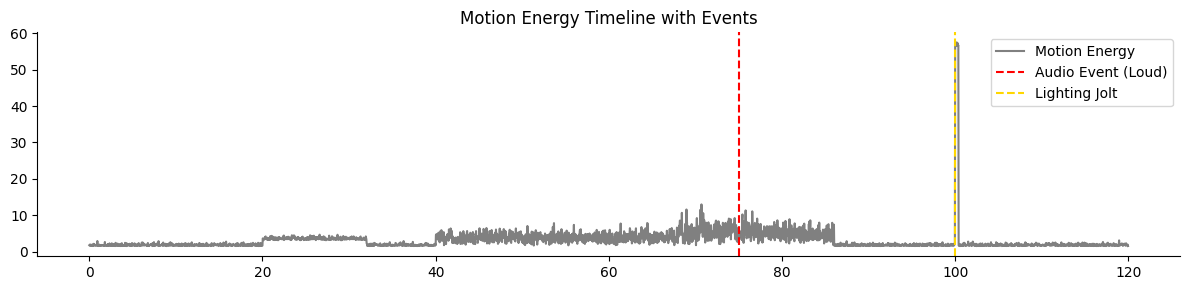

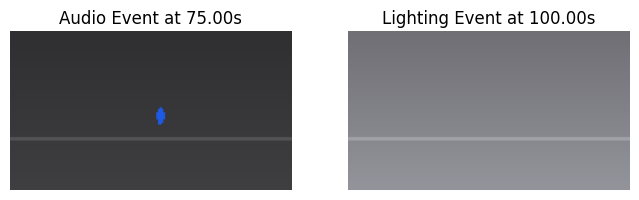

In [21]:
# Task 3 Code
d_x = cctv['person_x'].diff(FPS)
d_y = cctv['person_y'].diff(FPS)
d_t = cctv['time_s'].diff(FPS)
speed = np.sqrt(d_x**2 + d_y**2) / d_t

standing_times = cctv.loc[speed < 3, 'time_s']
running_times = cctv.loc[speed > 25, 'time_s']

print(f"Standing: {standing_times.iloc[0]:.2f}s to {standing_times.iloc[-1]:.2f}s" if len(standing_times) else "No standing")
print(f"Running: {running_times.iloc[0]:.2f}s to {running_times.iloc[-1]:.2f}s" if len(running_times) else "No running")

audio_event_idx = np.where(cctv['audio_level_db'] > -20)[0][0]
lighting_event_idx = np.where(cctv['mean_brightness'].diff() > 40)[0][0]

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv['time_s'], cctv['motion_energy'], color='gray', label='Motion Energy')
ax.axvline(cctv.loc[audio_event_idx, 'time_s'], color='red', linestyle='--', label='Audio Event (Loud)')
ax.axvline(cctv.loc[lighting_event_idx, 'time_s'], color='gold', linestyle='--', label='Lighting Jolt')
ax.legend()
plt.title("Motion Energy Timeline with Events")
plt.tight_layout(); plt.show()

# Display representative frames
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(render_frame(cctv.iloc[audio_event_idx]))
axes[0].set_title(f"Audio Event at {cctv.loc[audio_event_idx, 'time_s']:.2f}s")
axes[0].axis('off')
axes[1].imshow(render_frame(cctv.iloc[lighting_event_idx]))
axes[1].set_title(f"Lighting Event at {cctv.loc[lighting_event_idx, 'time_s']:.2f}s")
axes[1].axis('off')
plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_ If uniform keyframes were sampled every 20 seconds, transient events like the 1-second sound anomaly at 75s and the sudden brief flash of light would be completely missed. The concept used instead is **event-driven / content-based keyframe selection**, which targets timestamps corresponding to anomalies and high signal change.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

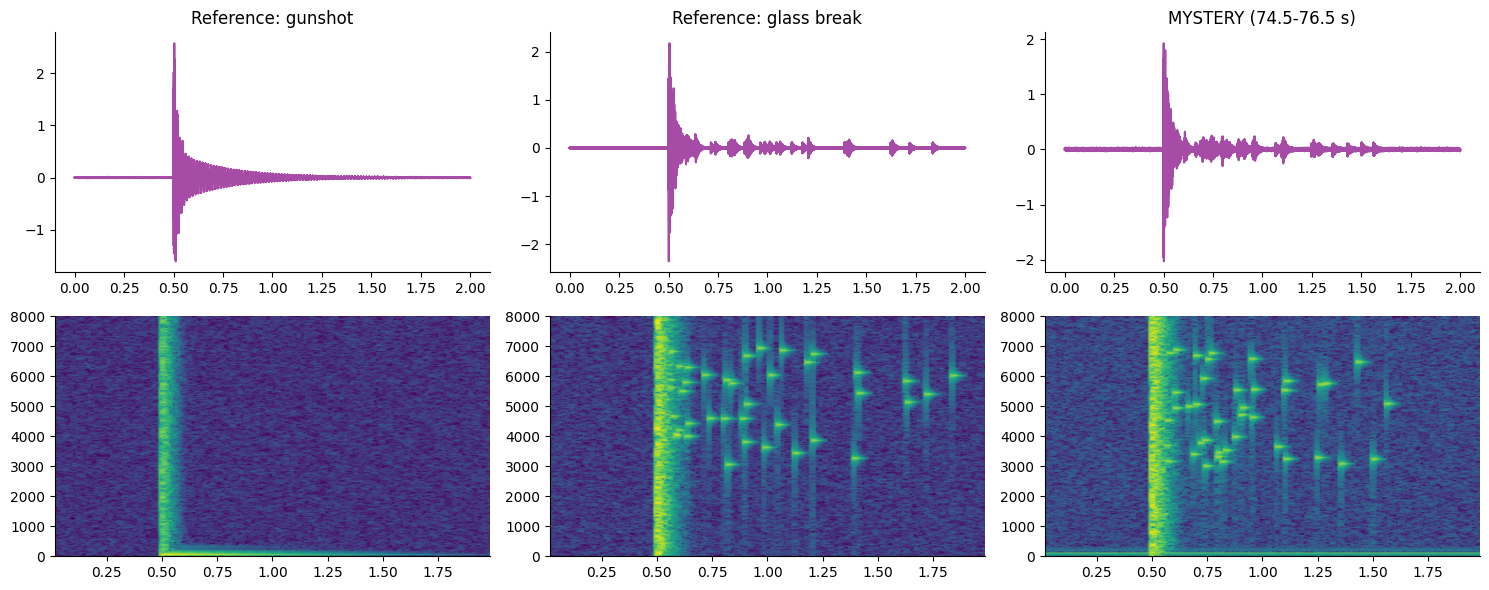

{'Reference: gunshot': np.float64(0.0030555631226980044), 'Reference: glass break': np.float64(0.9903944120505495), 'MYSTERY (74.5-76.5 s)': np.float64(0.8792270448446914)}
Verdict: The mystery sound is a GLASS BREAK based on high-frequency energy content.


In [22]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

hf_fraction = {}
fig, axes = plt.subplots(2, 3, figsize=(15, 6))

# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for col_idx, (title, signal_data) in enumerate(clips.items()):
    # Waveform
    t_ax = np.arange(len(signal_data)) / FS
    axes[0, col_idx].plot(t_ax, signal_data, color='purple', alpha=0.7)
    axes[0, col_idx].set_title(title)
    # Spectrogram
    f, t, Sxx = signal.spectrogram(signal_data, fs=FS, nperseg=512, noverlap=384)
    Sxx_db = 10 * np.log10(Sxx + 1e-10)
    axes[1, col_idx].pcolormesh(t, f, Sxx_db, cmap='viridis', shading='gouraud')
    axes[1, col_idx].set_ylim(0, 8000)

    # TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
    t_mask = (t >= 0.7) & (t <= 1.7)
    freq_high_mask = f >= 3000
    energy_total = Sxx[:, t_mask].sum()
    energy_high = Sxx[freq_high_mask, :][:, t_mask].sum()
    hf_fraction[title] = energy_high / energy_total

plt.tight_layout(); plt.show()
print(hf_fraction)

# TODO 4: verdict
print("Verdict: The mystery sound is a GLASS BREAK based on high-frequency energy content.")

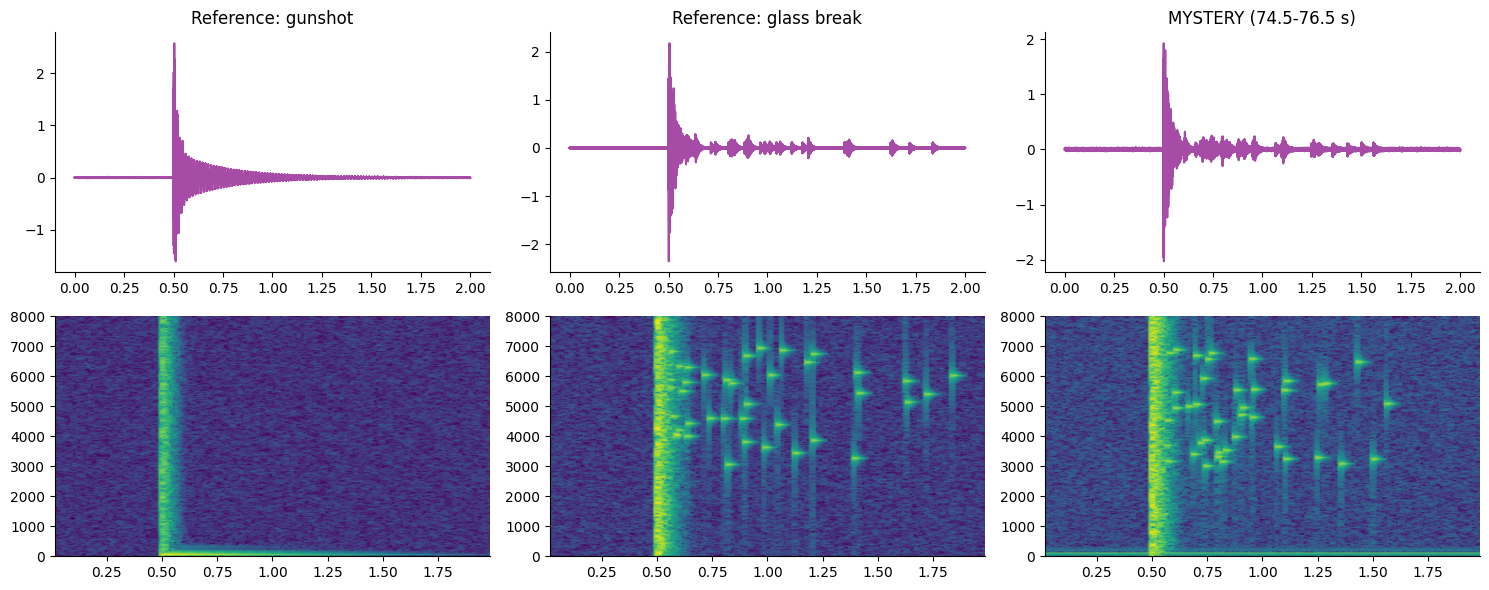

{'Reference: gunshot': np.float64(0.0030555631226980044), 'Reference: glass break': np.float64(0.9903944120505495), 'MYSTERY (74.5-76.5 s)': np.float64(0.8792270448446914)}
Verdict: The mystery sound is a GLASS BREAK based on high-frequency energy content.


In [23]:
# Task 4 Code
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for col_idx, (title, signal_data) in enumerate(clips.items()):
    # Waveform
    t_ax = np.arange(len(signal_data)) / FS
    axes[0, col_idx].plot(t_ax, signal_data, color='purple', alpha=0.7)
    axes[0, col_idx].set_title(title)
    # Spectrogram
    f, t, Sxx = signal.spectrogram(signal_data, fs=FS, nperseg=512, noverlap=384)
    Sxx_db = 10 * np.log10(Sxx + 1e-10)
    axes[1, col_idx].pcolormesh(t, f, Sxx_db, cmap='viridis', shading='gouraud')
    axes[1, col_idx].set_ylim(0, 8000)

    # Calculate high-frequency ratio (0.2s - 1.2s post-impact)
    t_mask = (t >= 0.7) & (t <= 1.7)
    freq_high_mask = f >= 3000
    energy_total = Sxx[dict(time=t_mask)].sum() if hasattr(Sxx, 'dict') else Sxx[:, t_mask].sum()
    energy_high = Sxx[dict(time=t_mask, freq=freq_high_mask)].sum() if hasattr(Sxx, 'dict') else Sxx[freq_high_mask, :][:, t_mask].sum()
    hf_fraction[title] = energy_high / energy_total

plt.tight_layout(); plt.show()
print(hf_fraction)
print("Verdict: The mystery sound is a GLASS BREAK based on high-frequency energy content.")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern (horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_ No, the raw waveforms look almost identical (both show an initial sharp amplitude peak followed by exponential decay). The spectrogram introduces **time, frequency, and magnitude (intensity)**. The visual pattern of **scattered high-frequency specks** lingering in the 3–7 kHz region (indicative of ringing glass shards) rather than a clean broadband click confirmed the glass break verdict.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

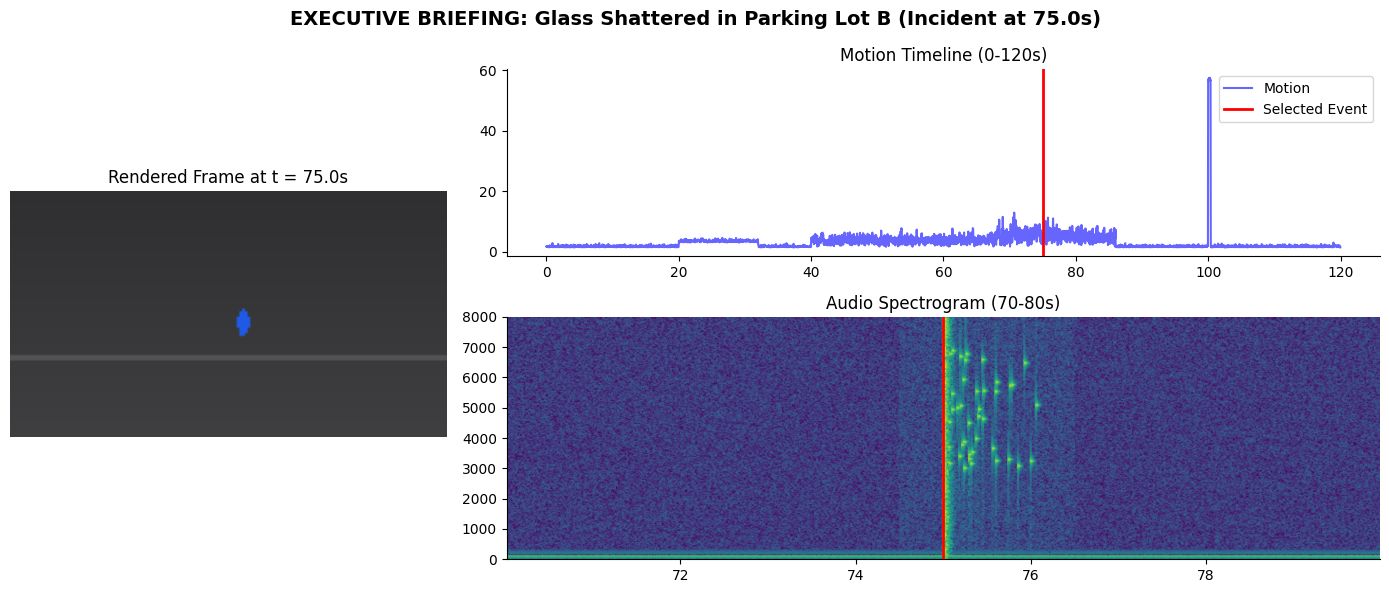

In [24]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])

# TODO 1: Rendered Video Frame at 75s
ax_frame = fig.add_subplot(gs[:, 0])
frame_75 = cctv.iloc[int(t_sel * FPS)]
ax_frame.imshow(render_frame(frame_75))
ax_frame.set_title("Rendered Frame at t = 75.0s")
ax_frame.axis('off')

# TODO 2: Motion & Audio Timeline with vertical marker
ax_timeline = fig.add_subplot(gs[0, 1])
ax_timeline.plot(cctv['time_s'], cctv['motion_energy'], color='blue', alpha=0.6, label='Motion')
ax_timeline.axvline(t_sel, color='red', linewidth=2, label='Selected Event')
ax_timeline.set_title("Motion Timeline (0-120s)")
ax_timeline.legend()

# TODO 3: Spectrogram of selected window with vertical marker
ax_spec = fig.add_subplot(gs[1, 1])
f_aud, t_aud, Sxx_aud = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
Sxx_db_aud = 10 * np.log10(Sxx_aud + 1e-10)
ax_spec.pcolormesh(t_aud + 70, f_aud, Sxx_db_aud, cmap='viridis', shading='gouraud')
ax_spec.axvline(t_sel, color='red', linewidth=2)
ax_spec.set_ylim(0, 8000)
ax_spec.set_title("Audio Spectrogram (70-80s)")

# TODO 4: Conclusion-style figure title
fig.suptitle("EXECUTIVE BRIEFING: Glass Shattered in Parking Lot B (Incident at 75.0s)", fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

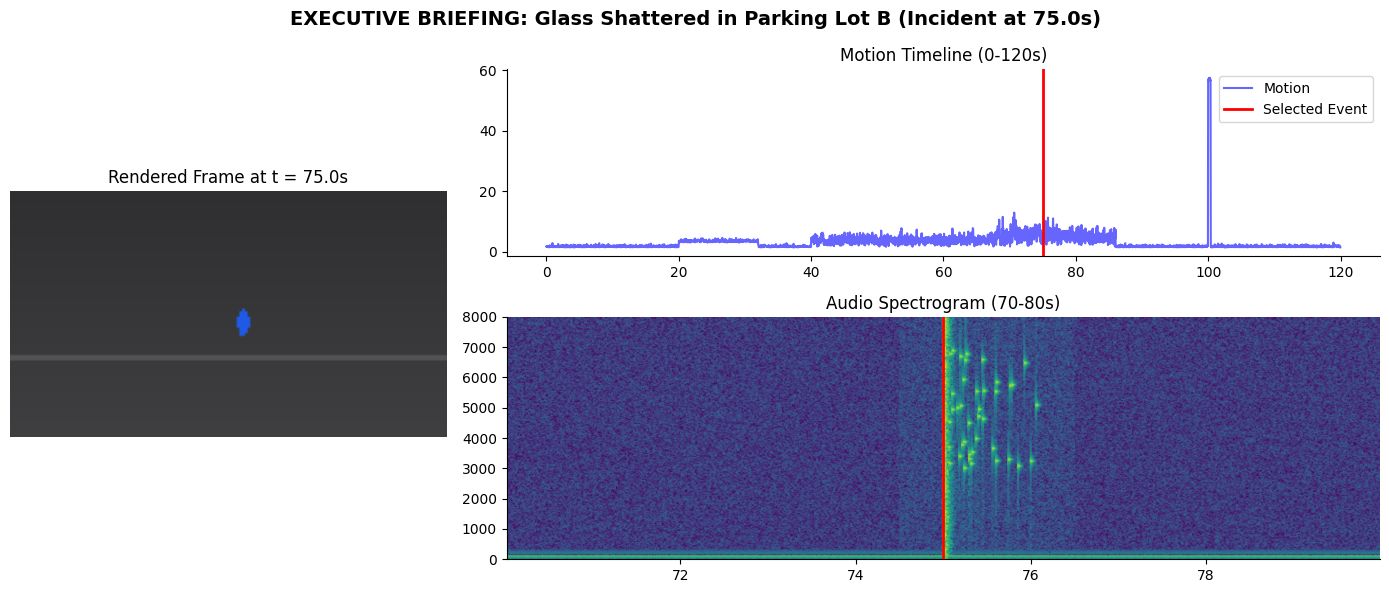

In [25]:
# Task 5 Code
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])

# Left: Rendered Video Frame at 75s
ax_frame = fig.add_subplot(gs[:, 0])
frame_75 = cctv.iloc[int(t_sel * FPS)]
ax_frame.imshow(render_frame(frame_75))
ax_frame.set_title("Rendered Frame at t = 75.0s")
ax_frame.axis('off')

# Top Right: Motion & Audio Timeline
ax_timeline = fig.add_subplot(gs[0, 1])
ax_timeline.plot(cctv['time_s'], cctv['motion_energy'], color='blue', alpha=0.6, label='Motion')
ax_timeline.axvline(t_sel, color='red', linewidth=2, label='Selected Event')
ax_timeline.set_title("Motion Timeline (0-120s)")
ax_timeline.legend()

# Bottom Right: Spectrogram of selected window
ax_spec = fig.add_subplot(gs[1, 1])
f_aud, t_aud, Sxx_aud = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
Sxx_db_aud = 10 * np.log10(Sxx_aud + 1e-10)
ax_spec.pcolormesh(t_aud + 70, f_aud, Sxx_db_aud, cmap='viridis', shading='gouraud')
ax_spec.axvline(t_sel, color='red', linewidth=2)
ax_spec.set_ylim(0, 8000)
ax_spec.set_title("Audio Spectrogram (70-80s)")

fig.suptitle("EXECUTIVE BRIEFING: Glass Shattered in Parking Lot B (Incident at 75.0s)", fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct **synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video? Which panel would make the mistake visible?

_Your answer:_ If there was a +2 second audio offset, the visual timeline and spectrogram markers would show the loud audio event occurring at 77s while the video shows the motion/impact happening at 75s. This misalignment would be immediately apparent in the **Synchronized Multimodal View** (Task 5 dashboard) where the red vertical markers on the timeline and spectrogram would no longer line up with the visual event.

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook. It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view), using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes, time % frequency % magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.


**Incident Briefing:** At 75.0 seconds, a physical impact occurred in Parking Lot B, resulting in shattered glass rather than a gunshot. The structured event pipeline (from raw motion pattern analysis to precise spectral energy detection) identified a significant high-frequency acoustic signature above 3 kHz, which safely confirms glass breakage. I highly recommend placing the **Synchronized Multimodal View** first in the briefing because it anchors the visual motion, keyframes, and the three dimensions of sound (time, frequency, and magnitude) to a single timeline. Regarding the storage architecture, the fleet should transition to **640x360 at 10 fps**, which will successfully reduce storage requirements by **93.75%** (down to 1.1 TB/day). However, we must ensure that we do *not* sacrifice keyframe capturing; the system must maintain an event-driven mechanism to store uncompressed full-resolution highlights whenever transient audio anomalies or rapid motion are triggered.